# 07_Predicted_TAS2R_agonist_and_non-agonist_complexes

In [1]:
import pandas as pd
import numpy as np
import os
import json
from tqdm import tqdm
from scipy.stats import pearsonr
import yaml

import sys
sys.path.append('../src/TAS2Rs_cofolding_utils/')
from other import read_json

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
palette = sns.color_palette('Set1')
custom_palette = {'agonist': palette[0], 'non-agonist': palette[1]}

In [3]:
TAS2R_agonists = pd.read_csv('../data/TAS2R_agonists.csv')

try:
    TAS2R_non_agonists = pd.read_csv('../data/TAS2R_non-agonists.csv')
    TAS2R_associations = pd.concat([TAS2R_agonists, TAS2R_non_agonists], ignore_index=True)
except:
    TAS2R_associations = TAS2R_agonists.copy()
    
rID_receptor_name =  TAS2R_associations[['rID', 'receptor name']].drop_duplicates().set_index('rID')['receptor name'].to_dict()
hTAS2R_rids = TAS2R_associations[TAS2R_associations['organism'] == 'Human']['rID'].sort_values().unique().tolist()

### Prepare configs for Boltz-2

In [4]:
directory = 'Cofolded_TAS2R_non-agonists'
path_to_predictions = os.path.join('../predictions', directory)

path_to_config_directory = os.path.abspath(os.path.join('../configs/', directory))
if not os.path.exists(path_to_config_directory):
   os.makedirs(path_to_config_directory)

In [5]:
for _, row in TAS2R_non_agonists.iterrows():
    # create config
    config_content = {'sequences': [{'protein': {'id': 'R', 'sequence': row['sequence']}}, 
                                    {'ligand': {'id': 'L', 'smiles': row['standardized smiles']}}],
                      'properties': [{'affinity': {'binder': 'L'}}]}
    # save config
    config_name = f'{row['cID']}-{row['rID']}.yaml'
    path_to_config = os.path.join(path_to_config_directory, config_name)
    with open(path_to_config, 'w') as out:
      yaml.safe_dump(config_content, out, sort_keys=False, allow_unicode=True)

### Run Boltz-2

In [6]:
# !boltz predict $path_to_config_directory --out_dir $path_to_predictions --diffusion_samples 5 --output_format pdb --use_msa_server

### Load co-folding results

In [7]:
cofolding_results = []

for _, row in tqdm(TAS2R_associations.iterrows(), total=len(TAS2R_associations)):
    
    directory = row['complex']
    association = row['association']
    cid = row['cID']
    rid = row['rID']
    
    if association == 'positive':
        path_to_cofolding_results = '../predictions/Cofolded_TAS2R_agonists/'
    elif association == 'negative':
        path_to_cofolding_results = '../predictions/Cofolded_TAS2R_non-agonists/'
    else:
        raise ValueError(f'Unknown association type: {association}')

    path_to_directory = os.path.join(path_to_cofolding_results, directory)
    
    affinity_file = f'affinity_{directory}.json'
    path_to_affinity_file = os.path.join(path_to_directory, affinity_file)
    
    if os.path.isfile(path_to_affinity_file):
        affinity_data = read_json(path_to_affinity_file)
    else:
        continue

    pdb_files = [file for file in os.listdir(path_to_directory) if file.endswith('.pdb')]

    for pdb_file in sorted(pdb_files):

        confidence_file = f"confidence_{pdb_file.replace('.pdb', '.json')}"
        path_to_confidence_file = os.path.join(path_to_directory, confidence_file)

        if os.path.isfile(path_to_confidence_file):
            confidence_data = read_json(path_to_confidence_file)
        else:
            continue
        
        cofolding_results.append([directory, affinity_data, confidence_data])
        
cofolding_results_df = pd.DataFrame(cofolding_results, columns=['complex', 'affinity data', 'confidence data'])
cofolding_results_df = cofolding_results_df.merge(TAS2R_associations, on='complex')

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8486/8486 [15:28<00:00,  9.14it/s]


In [8]:
cofolding_results_df['iptm'] = cofolding_results_df['confidence data'].apply(lambda confidence_data: confidence_data['iptm'])

In [9]:
reliable_predictions = {}

for complex_name, sub_df in cofolding_results_df.groupby('complex'):
    mean_iptm = sub_df['iptm'].mean()
    reliable_predictions[complex_name] = bool(mean_iptm >= 0.75)
cofolding_results_df['reliable prediction'] = cofolding_results_df['complex'].map(reliable_predictions)

In [10]:
cofolding_results_df.to_excel('../data/BitterDB_TP_TN_data_iptm.xlsx', index=False)

In [11]:
cofolding_results_df.drop_duplicates('complex')[['reliable prediction', 'association']].value_counts()

reliable prediction  association
True                 negative       6449
                     positive       1514
False                negative        475
                     positive         41
Name: count, dtype: int64

In [12]:
cofolding_results_df.drop_duplicates('complex')['EC50, μM'].notna().value_counts()

EC50, μM
False    8027
True      452
Name: count, dtype: int64

In [13]:
cofolding_results_df = cofolding_results_df[cofolding_results_df['reliable prediction']].reset_index(drop=True)

In [14]:
cofolding_results_df['affinity predicted value'] = cofolding_results_df['affinity data'].apply(lambda affinity_data: affinity_data['affinity_pred_value'])

In [15]:
affinity_value_distr = cofolding_results_df.drop_duplicates(subset=['cID', 'rID'], ignore_index=True).copy()
affinity_value_distr['log10(EC50), M'] = affinity_value_distr['log10(EC50), μM'] - 6
affinity_value_distr['affinity predicted value, M'] = affinity_value_distr['affinity predicted value'] - 6
affinity_value_distr['category'] = affinity_value_distr['association'].map({'positive': 'agonist', 'negative': 'non-agonist'})

### Agonists and non-agonists distribution

<Axes: xlabel='human TAS2R', ylabel='\n# molecules'>

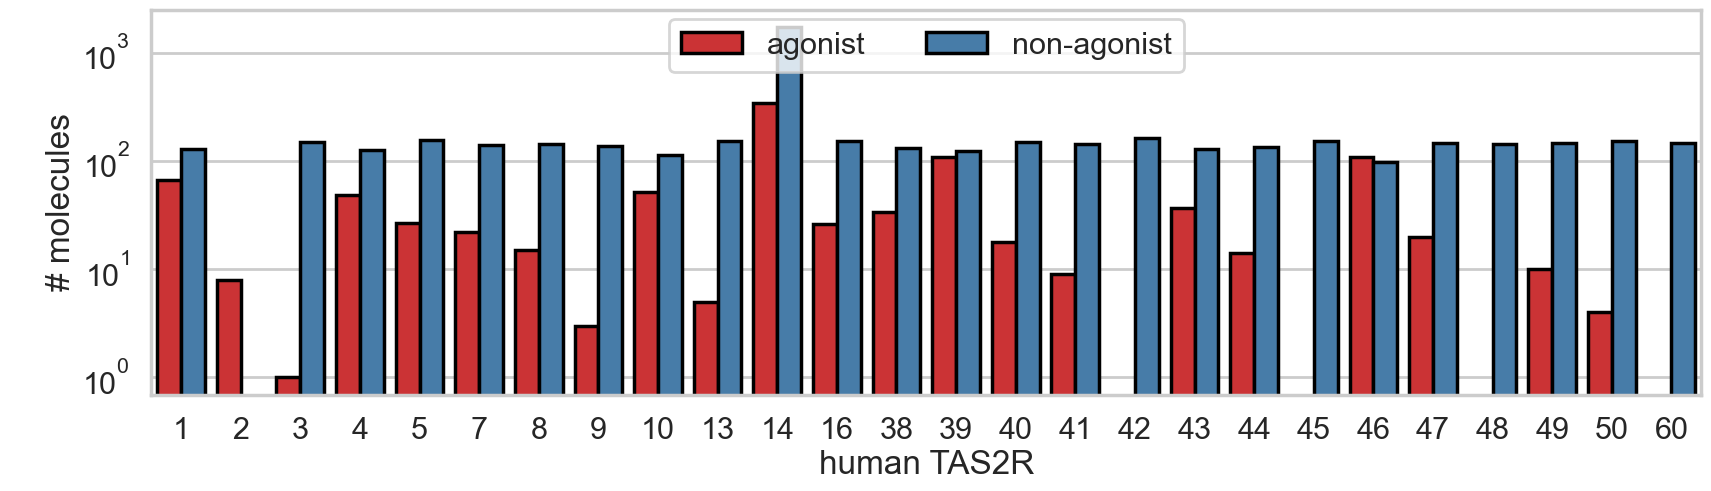

In [16]:
sns.set(rc={'figure.figsize':(20, 5)}, style='whitegrid', context='poster')
distr = affinity_value_distr[affinity_value_distr['rID'] <= 60][['rID', 'category']].value_counts().reset_index()
chart = sns.barplot(distr, x='rID', y='count', hue='category', hue_order=custom_palette.keys(), palette=custom_palette, linewidth=2.5, edgecolor='black')
chart.set(xlabel='human TAS2R', ylabel='\n# molecules', yscale='log')
chart.legend(title='')
sns.move_legend(chart, 'lower center', bbox_to_anchor=(0.5, 0.8), ncol=2)
chart.figure.savefig('../figures/main/Figure 4A Numbers of agonists and non-agonists of human TAS2Rs.png', dpi=300, bbox_inches='tight')
chart

### Receptor distribution of predicted affinity values for agonists and non-agonists 

<Axes: xlabel='human TAS2R', ylabel='predicted affinity\nlog(IC50), M'>

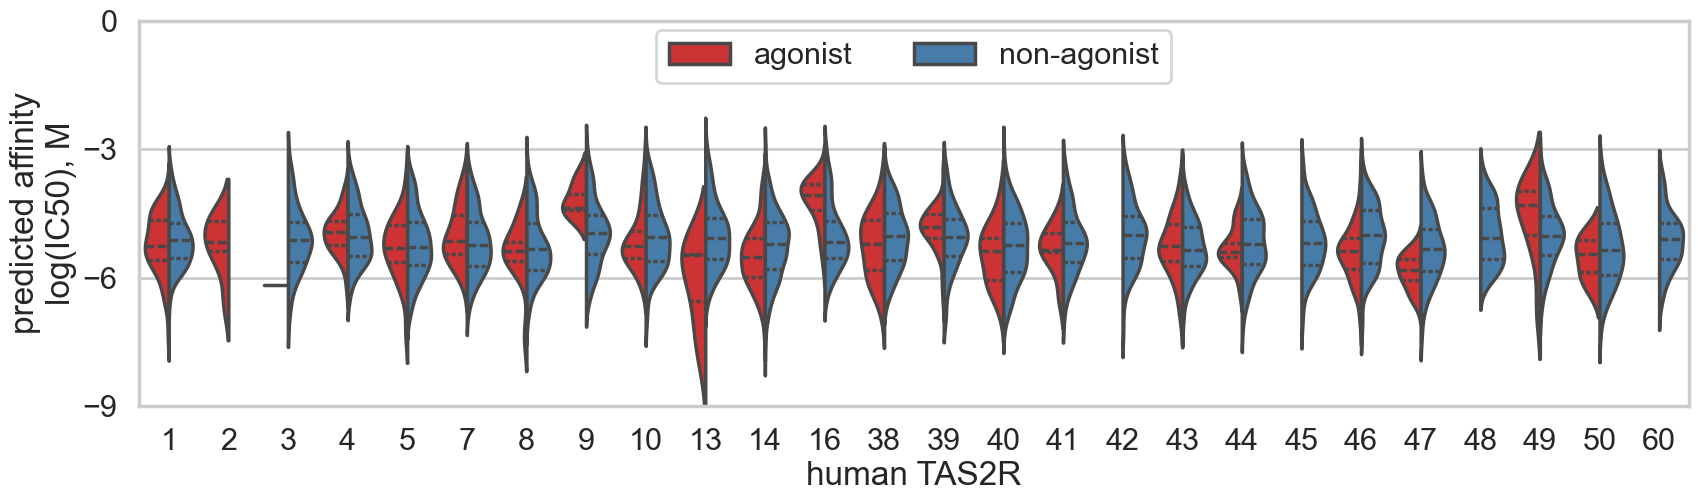

In [17]:
sns.set(rc={'figure.figsize':(20, 5)}, style='whitegrid', context='poster')
distr = affinity_value_distr[affinity_value_distr['rID'] <= 60].reset_index(drop=True)
chart = sns.violinplot(distr, x='rID', y='affinity predicted value, M', hue='category', hue_order=custom_palette.keys(), palette=custom_palette, split=True, inner='quart', density_norm='width')
chart.set(xlabel='human TAS2R', ylabel='predicted affinity\nlog(IC50), M', ylim=(-9, 0), yticks=range(0, -10, -3))
chart.legend(title='')
sns.move_legend(chart, 'lower center', bbox_to_anchor=(0.5, 0.8), ncol=2)
chart.figure.savefig('../figures/main/Figure 4B Predicted affinity values for agonists and non-agonists of human TAS2Rs.png', dpi=300, bbox_inches='tight')
chart

### Correletion between experimental and predicted affinity values

<Axes: title={'center': 'Pearson coefficient: 0.58\n444 agonists with known EC50 values'}, xlabel='experimental functional potency\nlog(EC50), M', ylabel='predicted affinity\nlog(IC50), M'>

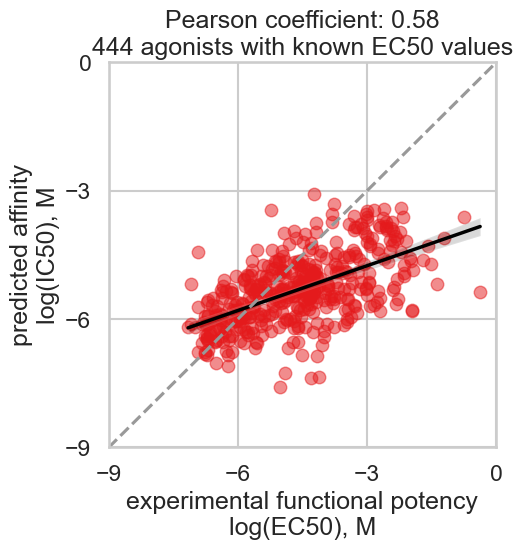

In [18]:
distr = affinity_value_distr.dropna(subset='log10(EC50), M', ignore_index=True)

pearson_coefficient, _ = pearsonr(x=distr['log10(EC50), M'], y=distr['affinity predicted value, M'])

sns.set(rc={'figure.figsize':(5, 5)}, style='whitegrid', context='talk')
chart = sns.regplot(distr, x='log10(EC50), M', y='affinity predicted value, M', scatter_kws={'color': palette[0], 'alpha': 0.5}, line_kws={'color': 'black', 'linewidth': 2.5},)
chart.set(title=f'Pearson coefficient: {pearson_coefficient.round(2)}\n{len(distr)} agonists with known EC50 values', xlabel='experimental functional potency\nlog(EC50), M', ylabel='predicted affinity\nlog(IC50), M', xlim=(-9, 0), ylim=(-9, 0), xticks=range(0, -10, -3), yticks=range(0, -10, -3))
chart.axline((0, 0), slope=1, linestyle='--', color=palette[8])

chart.figure.savefig('../figures/main/Figure 4C Correlation between predicted and experimental TAS2R affinity values.png', dpi=300, bbox_inches='tight')
chart

### Correletion between experimental and predicted affinity values

In [19]:
pearson_coefficient_distr = []
for rid in hTAS2R_rids:
    sub_df = affinity_value_distr[affinity_value_distr['rID'] == rid].dropna(subset='log10(EC50), M', ignore_index=True)
    ligands_number = len(sub_df)
    if ligands_number >= 2:
        pearson_coefficient, _ = pearsonr(x=sub_df['log10(EC50), M'], y=sub_df['affinity predicted value, M'])
    else:
        pearson_coefficient = 0
    pearson_coefficient_distr.append([rid, pearson_coefficient, ligands_number])
pearson_coefficient_distr = pd.DataFrame(pearson_coefficient_distr, columns=['rID', 'pearson coefficient', 'ligands number'])

<Axes: xlabel='human TAS2R', ylabel='Pearson coefficient'>

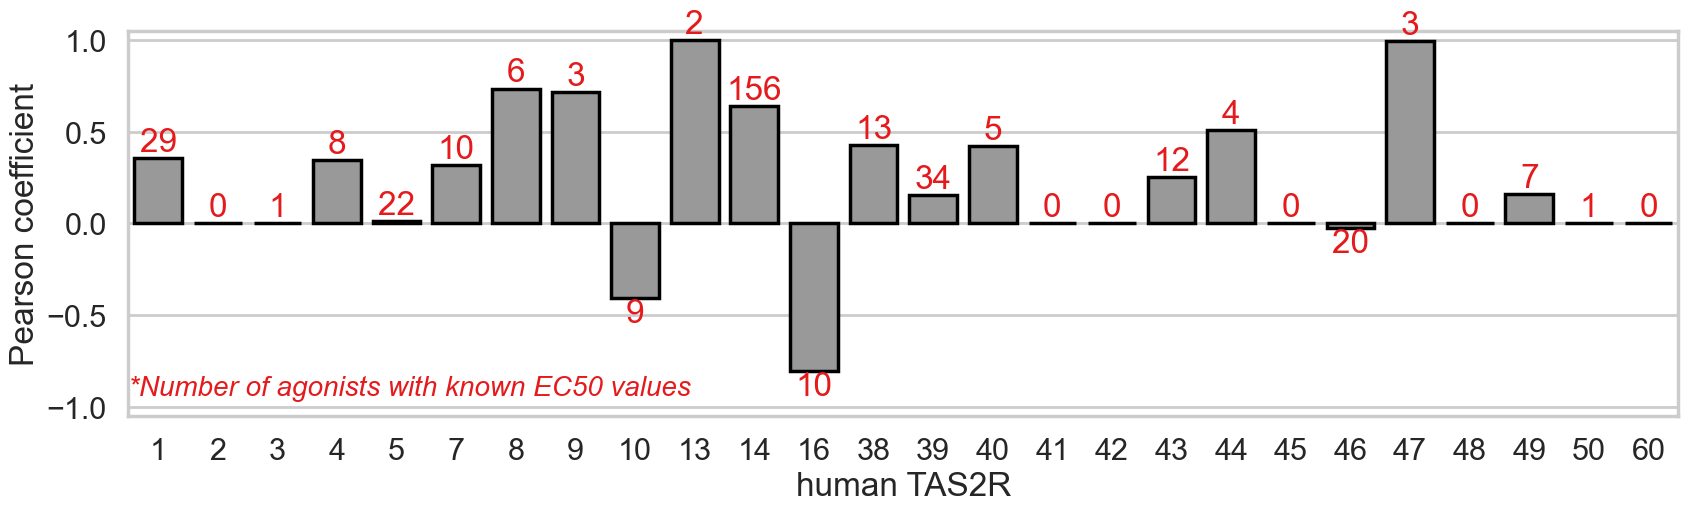

In [20]:
sns.set(rc={'figure.figsize':(20, 5)}, style='whitegrid', context='poster')
chart = sns.barplot(pearson_coefficient_distr, x='rID', y='pearson coefficient', color=palette[8], linewidth=2.5, edgecolor='black')
chart.set(xlabel='human TAS2R', ylabel='Pearson coefficient', ylim=(-1.05, 1.05), yticks=np.arange(-1.0, 1.5, 0.5))

chart.text(x=-0.5, y=-0.9, s='*Number of agonists with known EC50 values', va='center', ha='left', color=palette[0], fontstyle='italic', fontsize=20)
for i, row in pearson_coefficient_distr.iterrows():
    pearson_coefficient = row['pearson coefficient']
    if pearson_coefficient >= 0:
        va = 'bottom'
    else:
        va = 'top'
    ha = 'center'
    chart.text(x=i, y=row['pearson coefficient'], s=int(row['ligands number']), va=va, ha=ha, color=palette[0])

chart.figure.savefig('../figures/supplementary/Supplementary Figure 5 Distribution of Pearson coefficients for predicted affinity values.png', dpi=300, bbox_inches='tight')
chart

In [22]:
pearson_coefficient_distr[pearson_coefficient_distr['ligands number'] >= 5]

,rID,pearson coefficient,ligands number
0,1,0.356937,29
3,4,0.345528,8
4,5,0.010563,22
5,7,0.315975,10
6,8,0.735549,6
8,10,-0.405697,9
10,14,0.641185,156
11,16,-0.804631,10
12,38,0.428625,13
13,39,0.155387,34
